# Реализация Полиномиальной Регрессии


In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

In [ ]:
class CustomPolynomialRegression:
   
    def __init__(self, degree=2, method='ols', lr=0.05, epochs=1500, alpha=0.0, scale_features=True):
        self.degree = degree                  
        self.method = method                  
        self.lr = lr                          
        self.epochs = epochs                  
        self.alpha = alpha                    
        self.scale_features = scale_features  
        
        self.weights_ = None
        self.intercept_ = None
        self.mean_ = None
        self.std_ = None
        self.combinations_ = []               
        self.loss_history_ = []

    def _fit_transform_poly(self, X, is_fitting=True):
    
        m, d = X.shape
        if is_fitting:
            self.combinations_ = []
            for deg in range(1, self.degree + 1):
                for comb in itertools.combinations_with_replacement(range(d), deg):
                    self.combinations_.append(comb)
                    
        poly_columns = []
        for comb in self.combinations_:
            col_prod = np.prod(X[:, comb], axis=1)
            poly_columns.append(col_prod)
            
        X_poly = np.column_stack(poly_columns) if poly_columns else np.empty((m, 0))
        

        if self.scale_features and X_poly.shape[1] > 0:
            if is_fitting:
                self.mean_ = np.mean(X_poly, axis=0)
                self.std_ = np.std(X_poly, axis=0)
                
                self.std_[self.std_ < 1e-12] = 1.0
            X_poly = (X_poly - self.mean_) / self.std_
            
        return X_poly

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()
        if X.ndim == 1:
            X = X.reshape(-1, 1)
            
        X_poly = self._fit_transform_poly(X, is_fitting=True)
        m, d_poly = X_poly.shape
        X_b = np.hstack([np.ones((m, 1)), X_poly])

        if self.method == 'ols':
            reg_matrix = self.alpha * np.eye(d_poly + 1)
            reg_matrix[0, 0] = 0.0 
            
            theta = np.linalg.pinv(X_b.T @ X_b + reg_matrix) @ (X_b.T @ y)
            self.intercept_ = float(theta[0])
            self.weights_ = theta[1:]
            
        elif self.method == 'gd':
            theta = np.zeros(d_poly + 1)
            self.loss_history_ = []
            for _ in range(self.epochs):
                errors = (X_b @ theta) - y
                reg_grad = self.alpha * np.r_[0.0, theta[1:]]
                grad = (1.0 / m) * (X_b.T @ errors + reg_grad)
                theta -= self.lr * grad
                
                loss = (np.mean(errors ** 2) / 2.0) + (self.alpha / (2.0 * m)) * np.sum(theta[1:] ** 2)
                self.loss_history_.append(loss)
                
            self.intercept_ = float(theta[0])
            self.weights_ = theta[1:]
        else:
            raise ValueError("Параметр method должен быть 'ols' или 'gd'.")
            
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_poly = self._fit_transform_poly(X, is_fitting=False)
        return X_poly @ self.weights_ + self.intercept_

    def score(self, X, y):
        y_true = np.asarray(y, dtype=np.float64).ravel()
        y_pred = self.predict(X)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        return float(1.0 - (ss_res / ss_tot))

## Тестирование и сравнение

Degree=1 (Недообучение)                    | Train R2: 0.549 | Test R2: 0.587
Degree=3 (Оптимальный полином)             | Train R2: 0.915 | Test R2: 0.981
Degree=14, alpha=0 (Переобучение)          | Train R2: 0.946 | Test R2: 0.891
Degree=14, alpha=0.5 (С L2-регуляризацией) | Train R2: 0.897 | Test R2: 0.925


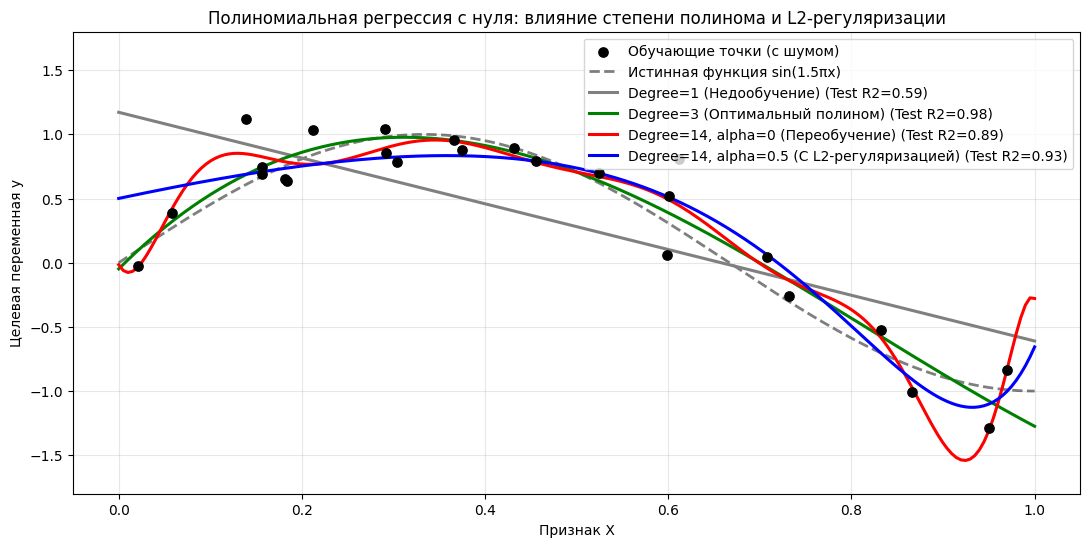

In [3]:
# Генерируем нелинейную зависимость y = sin(1.5 * pi * x) с шумом
np.random.seed(42)
X_train = np.sort(np.random.uniform(0, 1, 25)).reshape(-1, 1)
y_train = np.sin(1.5 * np.pi * X_train).ravel() + np.random.normal(0, 0.2, size=len(X_train))

X_grid = np.linspace(0, 1, 200).reshape(-1, 1)
y_true_grid = np.sin(1.5 * np.pi * X_grid).ravel()

# Обучаем 4 варианта нашего класса
poly_deg1 = CustomPolynomialRegression(degree=1, alpha=0.0).fit(X_train, y_train)
poly_deg3 = CustomPolynomialRegression(degree=3, alpha=0.0).fit(X_train, y_train)
poly_deg14_overfit = CustomPolynomialRegression(degree=14, alpha=0.0).fit(X_train, y_train)
poly_deg14_ridge = CustomPolynomialRegression(degree=14, alpha=0.5).fit(X_train, y_train)

plt.figure(figsize=(13, 6))
plt.scatter(X_train, y_train, color='black', s=45, zorder=5, label='Обучающие точки (с шумом)')
plt.plot(X_grid, y_true_grid, 'k--', alpha=0.5, linewidth=2, label='Истинная функция sin(1.5πx)')

for name, model, color in [
    ("Degree=1 (Недообучение)", poly_deg1, "gray"),
    ("Degree=3 (Оптимальный полином)", poly_deg3, "green"),
    ("Degree=14, alpha=0 (Переобучение)", poly_deg14_overfit, "red"),
    ("Degree=14, alpha=0.5 (С L2-регуляризацией)", poly_deg14_ridge, "blue")
]:
    y_pred_grid = model.predict(X_grid)
    r2_test = model.score(X_grid, y_true_grid)
    print(f"{name:<42} | Train R2: {model.score(X_train, y_train):.3f} | Test R2: {r2_test:.3f}")
    plt.plot(X_grid, y_pred_grid, color=color, linewidth=2.2, label=f"{name} (Test R2={r2_test:.2f})")

plt.ylim(-1.8, 1.8)
plt.title("Полиномиальная регрессия с нуля: влияние степени полинома и L2-регуляризации")
plt.xlabel("Признак X")
plt.ylabel("Целевая переменная y")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.show()